In [1]:
import pandas as pd
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_wine
from sklearn.metrics import silhouette_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier, export_graphviz
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from scipy.spatial.distance import pdist
from scipy.cluster import hierarchy
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import graphviz

# Задача 1. Clustering

## 1. Зареждане на данните

Данните се зареждат от cust.csv, премахват се колоната CUST_ID и редовете, които имат празни полета.

In [2]:
url = "cust.csv"
df = pd.read_csv(url)

customers = df.drop('CUST_ID', axis=1)
customers = customers.dropna()

cols = customers.columns

customers.head(10)

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,40.900749,0.818182,95.40,0.00,95.40,0.000000,0.166667,0.000000,0.083333,0.00,0,2,1000.0,201.802084,139.509787,0.000000,12
1,3202.467416,0.909091,0.00,0.00,0.00,6442.945483,0.000000,0.000000,0.000000,0.25,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,2495.148862,1.000000,773.17,773.17,0.00,0.000000,1.000000,1.000000,0.000000,0.00,0,12,7500.0,622.066742,627.284787,0.000000,12
4,817.714335,1.000000,16.00,16.00,0.00,0.000000,0.083333,0.083333,0.000000,0.00,0,1,1200.0,678.334763,244.791237,0.000000,12
5,1809.828751,1.000000,1333.28,0.00,1333.28,0.000000,0.666667,0.000000,0.583333,0.00,0,8,1800.0,1400.057770,2407.246035,0.000000,12
6,627.260806,1.000000,7091.01,6402.63,688.38,0.000000,1.000000,1.000000,1.000000,0.00,0,64,13500.0,6354.314328,198.065894,1.000000,12
7,1823.652743,1.000000,436.20,0.00,436.20,0.000000,1.000000,0.000000,1.000000,0.00,0,12,2300.0,679.065082,532.033990,0.000000,12
8,1014.926473,1.000000,861.49,661.49,200.00,0.000000,0.333333,0.083333,0.250000,0.00,0,5,7000.0,688.278568,311.963409,0.000000,12
9,152.225975,0.545455,1281.60,1281.60,0.00,0.000000,0.166667,0.166667,0.000000,0.00,0,3,11000.0,1164.770591,100.302262,0.000000,12
10,1293.124939,1.000000,920.12,0.00,920.12,0.000000,1.000000,0.000000,1.000000,0.00,0,12,1200.0,1083.301007,2172.697765,0.000000,12


## 2. Нормализиране

Използва се Z-scale нормализация. Стойностите на даден атрибут се привеждат към стандартна форма, така че да имат средна стойност 0 и стандартно отклонение 1. Това улеснява работата на алгоритмите за машинно обучение, тъй като елиминира влиянието на различните мащаби на данните.

In [3]:
scaler = StandardScaler()
customers_scaled = pd.DataFrame(scaler.fit_transform(customers), columns=cols)

customers_scaled.head()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,-0.744625,-0.370047,-0.429184,-0.359160,-0.354826,-0.468655,-0.820769,-0.686280,-0.717179,-0.681953,-0.479437,-0.517623,-0.962575,-0.543942,-0.305508,-0.537727,0.355181
1,0.764152,0.067679,-0.473208,-0.359160,-0.458839,2.568556,-1.236139,-0.686280,-0.926522,0.557022,0.099258,-0.597054,0.677204,0.796852,0.087689,0.212380,0.355181
2,0.426602,0.505405,-0.116413,0.099909,-0.458839,-0.468655,1.256077,2.646651,-0.926522,-0.681953,-0.479437,-0.120467,0.813852,-0.399503,-0.099906,-0.537727,0.355181
3,-0.373910,0.505405,-0.465825,-0.349660,-0.458839,-0.468655,-1.028455,-0.408536,-0.926522,-0.681953,-0.479437,-0.557339,-0.907916,-0.380165,-0.261131,-0.537727,0.355181
4,0.099551,0.505405,0.142062,-0.359160,0.994815,-0.468655,0.425339,-0.686280,0.538882,-0.681953,-0.479437,-0.279329,-0.743938,-0.132119,0.650363,-0.537727,0.355181


## 3. PCA (Principal Component Analysis)

PCA анализът се ползва с цел намаляване размерността на данните, идентифициране на основните характеристики и възможност за визуализация на резултатите.

In [4]:
pca = PCA(n_components=2)
customers_pca = pca.fit_transform(customers_scaled)

coefficients = pca.components_

feature_names = customers.columns

for i, component in enumerate(pca.components_, start=1):
    print(f"\nPCA Component {i}:")
    for feature, coef in zip(feature_names, component):
        print(f"{feature}: {coef:.4f}")


PCA Component 1:
BALANCE: 0.0920
BALANCE_FREQUENCY: 0.1098
PURCHASES: 0.4122
ONEOFF_PURCHASES: 0.3468
INSTALLMENTS_PURCHASES: 0.3371
CASH_ADVANCE: -0.0306
PURCHASES_FREQUENCY: 0.3237
ONEOFF_PURCHASES_FREQUENCY: 0.2948
PURCHASES_INSTALLMENTS_FREQUENCY: 0.2772
CASH_ADVANCE_FREQUENCY: -0.0991
CASH_ADVANCE_TRX: -0.0570
PURCHASES_TRX: 0.3911
CREDIT_LIMIT: 0.2101
PAYMENTS: 0.2637
MINIMUM_PAYMENTS: 0.0593
PRC_FULL_PAYMENT: 0.1306
TENURE: 0.0779

PCA Component 2:
BALANCE: 0.4060
BALANCE_FREQUENCY: 0.1277
PURCHASES: 0.0495
ONEOFF_PURCHASES: 0.0699
INSTALLMENTS_PURCHASES: -0.0115
CASH_ADVANCE: 0.4372
PURCHASES_FREQUENCY: -0.1866
ONEOFF_PURCHASES_FREQUENCY: -0.0147
PURCHASES_INSTALLMENTS_FREQUENCY: -0.1736
CASH_ADVANCE_FREQUENCY: 0.4300
CASH_ADVANCE_TRX: 0.4164
PURCHASES_TRX: -0.0119
CREDIT_LIMIT: 0.2438
PAYMENTS: 0.2642
MINIMUM_PAYMENTS: 0.1704
PRC_FULL_PAYMENT: -0.1957
TENURE: -0.0046


В PCA1 се вижда, че определящите колони са: 

PURCHASES: 0.4122  
PURCHASES_TRX: 0.3911  
ONEOFF_PURCHASES: 0.3468  
INSTALLMENTS_PURCHASES: 0.3371  
PURCHASES_FREQUENCY: 0.3237  
ONEOFF_PURCHASES_FREQUENCY: 0.2948  
PURCHASES_INSTALLMENTS_FREQUENCY: 0.2772  

В PCA2:

CASH_ADVANCE: 0.4372  
CASH_ADVANCE_FREQUENCY: 0.4300  
CASH_ADVANCE_TRX: 0.4164  
BALANCE: 0.4060

От тук може да намерим зависимост между клиенти, които пазаруват активно и такива, които теглят от сметката си.

## 4. Дендрограма на данните

(37285930,)


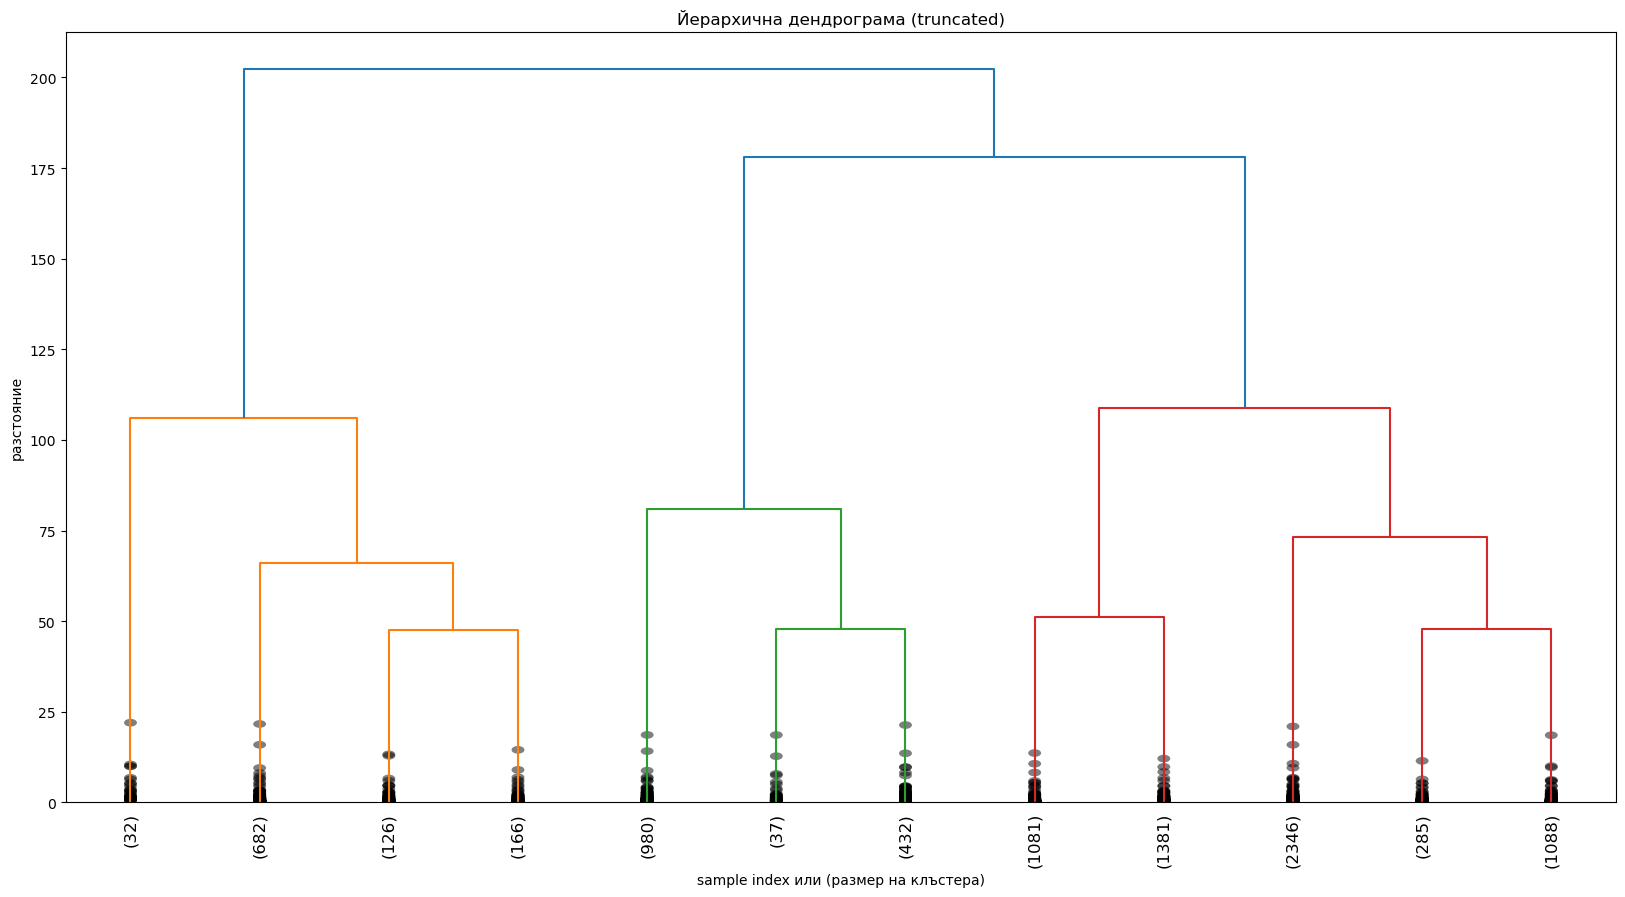

In [5]:
distance_mat = pdist(customers_pca)
print(distance_mat.shape)

Z = hierarchy.linkage(distance_mat, 'ward')

plt.figure(figsize=(20, 10))

plt.title('Йерархична дендрограма (truncated)')
plt.xlabel('sample index или (размер на клъстера)')
plt.ylabel('разстояние')
hierarchy.dendrogram(
    Z,
    truncate_mode='lastp',  # покажи само последните p = 12 сляти клъстера
    p=12,
    leaf_rotation=90.,
    leaf_font_size=12.,
    show_contracted=True,  # представа за разпределението в съкратените клони
)
plt.show()

Забелязват се 3 основни клъстера .

## 5. Метод на лакътя и Silhouette Score

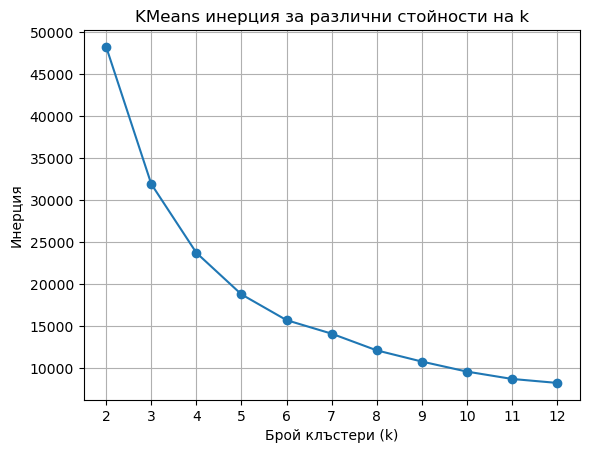

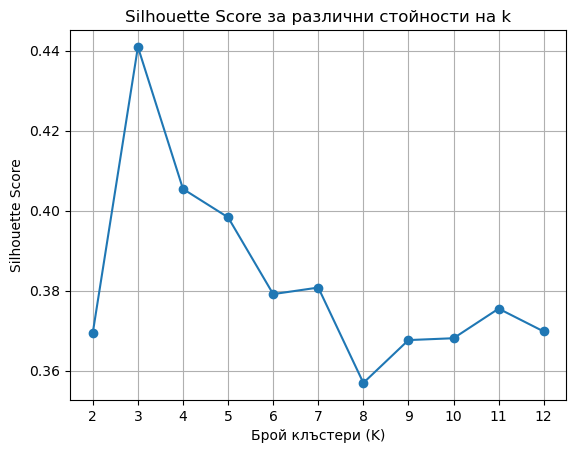

In [6]:
max_k = 12

inertia = []
scores = []
k_values = range(2, max_k + 1)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(customers_pca)
    score = silhouette_score(customers_pca, labels)
    scores.append(score)
    
    inertia.append(kmeans.inertia_)

plt.plot(k_values, inertia, marker='o')
plt.title('KMeans инерция за различни стойности на k')
plt.xlabel('Брой клъстери (k)')
plt.ylabel('Инерция')
plt.xticks(k_values)
plt.grid(True)
plt.show()

plt.plot(k_values, scores, marker='o')
plt.title('Silhouette Score за различни стойности на k')
plt.xlabel("Брой клъстери (K)")
plt.ylabel("Silhouette Score")
plt.xticks(k_values)
plt.grid(True)



## 6. K-Means

На базата на резултатите от йерархичната дендрограма, Метода на лакътя и Silhouette Score се вижда, че оптималният брой клъстери е 3 или 4. Избрала съм 3.

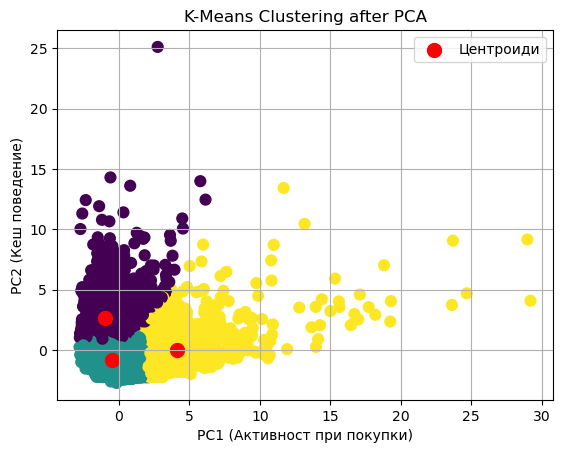

In [7]:
kmeans = KMeans(n_clusters = 3, random_state = 42)
kmeans_labels = kmeans.fit_predict(customers_pca)

plt.scatter(customers_pca[:, 0], customers_pca[:, 1], c=kmeans_labels, cmap='viridis', s=60)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=100, c='red', label='Центроиди')
plt.legend()
plt.grid(True)
plt.title('K-Means Clustering after PCA')
plt.xlabel('PC1 (Активност при покупки)')
plt.ylabel('PC2 (Кеш поведение)')
plt.show()

Наблюдава се разграничение на 3 групи купувачи: в лилаво - такива, които предимно теглят кеш, в жълто - активно пазаруващи и в зелено са пасивните клиенти.

## 7. DBSCAN

DBSCAN не работи добре за предоставените данни, тъй като гъстотата им е твърде голяма и е трудно да се определи стойност за eps. В резултат повечете данни се групират в един клъстер или голяма част се определя като шум.

In [8]:
dbscan = DBSCAN(eps=2, min_samples=3).fit(customers_pca)

dbscan_labels = dbscan.labels_

unique_labels, counts = np.unique(dbscan_labels, return_counts=True)
cluster_counts = dict(zip(unique_labels, counts))

print(cluster_counts)

{-1: 13, 0: 8604, 1: 19}


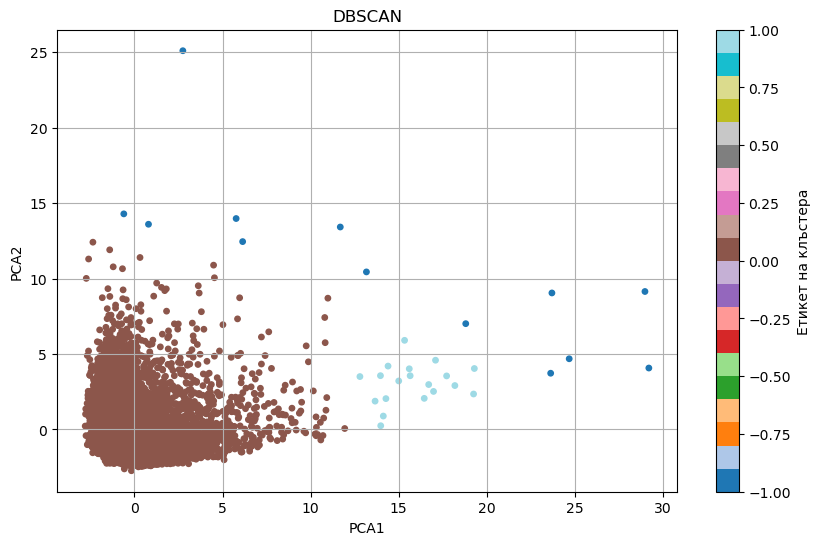

In [9]:
plt.figure(figsize=(10, 6))
scatter = plt.scatter(customers_pca[:, 0], customers_pca[:, 1], c=dbscan_labels, cmap='tab20', s=15)
plt.title('DBSCAN')
plt.xlabel('PCA1')
plt.ylabel('PCA2')
plt.colorbar(scatter, label='Етикет на клъстера')
plt.grid(True)
plt.show()

# Задача 2. Дървета

## 1. Зареждане на данни и разделяне на тестови и такива за обучение

Данните представляват различни характеристики на вино. Целта е според тях моделите да се обучат така, че да предвидят принадлежността към определен вид вино.

In [10]:
data = load_wine()
df = pd.DataFrame(data.data, columns=data.feature_names)

df['target'] = data.target

df.head(100)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,12.47,1.52,2.20,19.0,162.0,2.50,2.27,0.32,3.28,2.60,1.16,2.63,937.0,1
96,11.81,2.12,2.74,21.5,134.0,1.60,0.99,0.14,1.56,2.50,0.95,2.26,625.0,1
97,12.29,1.41,1.98,16.0,85.0,2.55,2.50,0.29,1.77,2.90,1.23,2.74,428.0,1
98,12.37,1.07,2.10,18.5,88.0,3.52,3.75,0.24,1.95,4.50,1.04,2.77,660.0,1


In [11]:
X = data.data
y = data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, random_state=42)

## 2. Decision Tree

In [12]:
params_dt = {'criterion': ['gini', 'entropy'],
           'max_depth': [1, 2, 3, 4, 5],
           'min_samples_leaf': [5, 10, 15, 20]}

grid_search_dt = GridSearchCV(DecisionTreeClassifier(), params_dt, cv=5)

grid_search_dt.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [1, 2, 3, 4, 5],
                         'min_samples_leaf': [5, 10, 15, 20]})

In [13]:
best_dt = grid_search_dt.best_estimator_

best_dt

DecisionTreeClassifier(max_depth=3, min_samples_leaf=5)

In [14]:
best_dt.criterion

'gini'

In [15]:
best_dt.score(X_train, y_train)

0.9758064516129032

In [16]:
print(classification_report(best_dt.predict(X_train), y_train))

              precision    recall  f1-score   support

           0       0.93      1.00      0.96        37
           1       1.00      0.94      0.97        53
           2       1.00      1.00      1.00        34

    accuracy                           0.98       124
   macro avg       0.97      0.98      0.98       124
weighted avg       0.98      0.98      0.98       124



In [17]:
best_dt.score(X_test, y_test)

0.9444444444444444

In [18]:
print(classification_report(best_dt.predict(X_test), y_test))

              precision    recall  f1-score   support

           0       0.89      1.00      0.94        17
           1       1.00      0.88      0.93        24
           2       0.93      1.00      0.96        13

    accuracy                           0.94        54
   macro avg       0.94      0.96      0.95        54
weighted avg       0.95      0.94      0.94        54



In [19]:
confusion_matrix(best_dt.predict(X_test), y_test)

array([[17,  0,  0],
       [ 2, 21,  1],
       [ 0,  0, 13]])

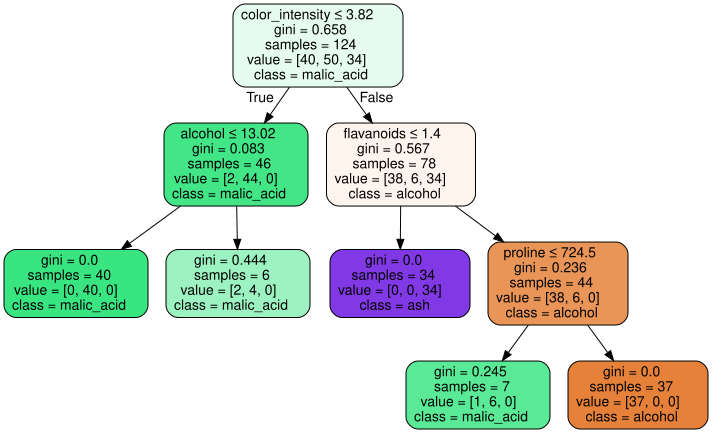

In [20]:
dot_data = export_graphviz(best_dt, out_file=None,
                     feature_names=data.feature_names,
                     class_names=data.feature_names,
                     filled=True, rounded=True,
                     special_characters=True)
graph = graphviz.Source(dot_data)
graph

## 3. Random Forest

In [21]:
params_rf = {'n_estimators': [50, 100, 150],'max_features': ['sqrt', 3]}

grid_search_rf = GridSearchCV(RandomForestClassifier(n_jobs=-1), params_rf, cv=5)

grid_search_rf.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(n_jobs=-1),
             param_grid={'max_features': ['sqrt', 3],
                         'n_estimators': [50, 100, 150]})

In [22]:
best_rf = grid_search_rf.best_estimator_

best_rf

RandomForestClassifier(max_features=3, n_estimators=50, n_jobs=-1)

In [23]:
best_rf.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 3,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 50,
 'n_jobs': -1,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

In [24]:
best_rf.score(X_test, y_test)

0.9814814814814815

In [25]:
print(classification_report(best_rf.predict(X_train), y_train))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        40
           1       1.00      1.00      1.00        50
           2       1.00      1.00      1.00        34

    accuracy                           1.00       124
   macro avg       1.00      1.00      1.00       124
weighted avg       1.00      1.00      1.00       124



In [26]:
print(classification_report(best_rf.predict(X_test), y_test))

              precision    recall  f1-score   support

           0       0.95      1.00      0.97        18
           1       1.00      0.95      0.98        22
           2       1.00      1.00      1.00        14

    accuracy                           0.98        54
   macro avg       0.98      0.98      0.98        54
weighted avg       0.98      0.98      0.98        54



In [27]:
best_rf.feature_importances_

array([0.09313892, 0.03006363, 0.01218962, 0.03501336, 0.02061292,
       0.068995  , 0.16408847, 0.00738754, 0.02614339, 0.19320656,
       0.05997674, 0.12901938, 0.16016449])

## 4. Ada Boost

In [28]:
params_ada = {'n_estimators': [50, 100, 150],
          'estimator__max_depth': [1, 2, 3],
          }

grid_search = GridSearchCV(AdaBoostClassifier(estimator=DecisionTreeClassifier(), algorithm='SAMME'), params_ada, cv=5)
grid_search.fit(X_train, y_train)

best_ada = grid_search.best_estimator_

best_ada.get_params()

{'algorithm': 'SAMME',
 'estimator__ccp_alpha': 0.0,
 'estimator__class_weight': None,
 'estimator__criterion': 'gini',
 'estimator__max_depth': 2,
 'estimator__max_features': None,
 'estimator__max_leaf_nodes': None,
 'estimator__min_impurity_decrease': 0.0,
 'estimator__min_samples_leaf': 1,
 'estimator__min_samples_split': 2,
 'estimator__min_weight_fraction_leaf': 0.0,
 'estimator__monotonic_cst': None,
 'estimator__random_state': None,
 'estimator__splitter': 'best',
 'estimator': DecisionTreeClassifier(max_depth=2),
 'learning_rate': 1.0,
 'n_estimators': 100,
 'random_state': None}

In [29]:
print(classification_report(best_ada.predict(X_test), y_test))

              precision    recall  f1-score   support

           0       1.00      0.95      0.97        20
           1       0.95      0.95      0.95        21
           2       0.93      1.00      0.96        13

    accuracy                           0.96        54
   macro avg       0.96      0.97      0.96        54
weighted avg       0.96      0.96      0.96        54



In [30]:
best_ada.feature_importances_

array([0.08905064, 0.01489371, 0.04382751, 0.03090327, 0.02963732,
       0.07557673, 0.34789326, 0.00396113, 0.02753318, 0.10110994,
       0.01772449, 0.06991959, 0.14796923])

При класификацията на данни се вижда, че алгоритъмът Random Forest има най-голяма точност. Определящият параметър е color_intensity.

## 5. Напишете Random Forest за класификация

In [34]:
from collections import Counter
from sklearn.datasets import load_iris
from sklearn.ensemble import RandomForestClassifier as SklearnRFC
from sklearn.metrics import accuracy_score

np.random.seed(42)

# Функции за ентропия и информация
def entropy(y):
    counts = np.bincount(y)
    probabilities = counts / len(y)
    return -np.sum([p * np.log2(p) for p in probabilities if p > 0])

def information_gain(y, x_column, threshold):
    parent_entropy = entropy(y)

    left_idx = x_column <= threshold
    right_idx = x_column > threshold

    if sum(left_idx) == 0 or sum(right_idx) == 0:
        return 0

    n = len(y)
    left_entropy = entropy(y[left_idx])
    right_entropy = entropy(y[right_idx])

    child_entropy = (sum(left_idx) / n) * left_entropy + (sum(right_idx) / n) * right_entropy
    return parent_entropy - child_entropy

# Собствено Decision Tree
class DecisionTreeClassifier:
    def __init__(self, max_depth=5, min_samples_split=2, max_features=None):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.max_features = max_features
        self.tree = None

    def fit(self, X, y, depth=0):
        self.n_classes = len(set(y))
        self.n_features = X.shape[1]
        self.features_indices = np.random.choice(self.n_features, self.max_features or self.n_features, replace=False)
        self.tree = self._build_tree(X, y, depth)

    def _build_tree(self, X, y, depth):
        n_samples, n_features = X.shape
        if (depth >= self.max_depth or len(set(y)) == 1 or n_samples < self.min_samples_split):
            return Counter(y).most_common(1)[0][0]

        best_gain = -1
        best_feat = None
        best_thresh = None
        for feat in self.features_indices:
            thresholds = np.unique(X[:, feat])
            for threshold in thresholds:
                gain = information_gain(y, X[:, feat], threshold)
                if gain > best_gain:
                    best_gain = gain
                    best_feat = feat
                    best_thresh = threshold

        if best_gain == 0:
            return Counter(y).most_common(1)[0][0]

        left_idx = X[:, best_feat] <= best_thresh
        right_idx = X[:, best_feat] > best_thresh

        left = self._build_tree(X[left_idx], y[left_idx], depth + 1)
        right = self._build_tree(X[right_idx], y[right_idx], depth + 1)

        return (best_feat, best_thresh, left, right)

    def _predict_sample(self, x, node):
        if not isinstance(node, tuple):
            return node
        feat, thresh, left, right = node
        return self._predict_sample(x, left if x[feat] <= thresh else right)

    def predict(self, X):
        return np.array([self._predict_sample(x, self.tree) for x in X])

# Собствен Random Forest
class RandomForestClassifier:
    def __init__(self, n_estimators=10, max_depth=5, min_samples_split=2, max_features=None):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.max_features = max_features
        self.trees = []

    def fit(self, X, y):
        self.trees = []
        for _ in range(self.n_estimators):
            idxs = np.random.choice(len(X), size=len(X), replace=True)
            X_sample, y_sample = X[idxs], y[idxs]
            tree = DecisionTreeClassifier(max_depth=self.max_depth,
                                          min_samples_split=self.min_samples_split,
                                          max_features=self.max_features)
            tree.fit(X_sample, y_sample)
            self.trees.append(tree)

    def predict(self, X):
        tree_preds = np.array([tree.predict(X) for tree in self.trees])
        return np.apply_along_axis(lambda x: Counter(x).most_common(1)[0][0], axis=0, arr=tree_preds)

# Пример с Iris Dataset
iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)

# Собствен модел
my_rf = RandomForestClassifier(n_estimators=10, max_depth=5, max_features=2)
my_rf.fit(X_train, y_train)
y_pred_my = my_rf.predict(X_test)
acc_my = accuracy_score(y_test, y_pred_my)

# sklearn модел
sk_rf = SklearnRFC(n_estimators=10, max_depth=5, max_features=2, random_state=42)
sk_rf.fit(X_train, y_train)
y_pred_sk = sk_rf.predict(X_test)
acc_sk = accuracy_score(y_test, y_pred_sk)

print(f"My Random Forest Accuracy: {acc_my:.3f}")
print(f"Sklearn Random Forest Accuracy: {acc_sk:.3f}")

My Random Forest Accuracy: 0.978
Sklearn Random Forest Accuracy: 1.000
